In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
DATASET_PATH = '../data/raw/student-mental-health.csv'



In [3]:
df = pd.read_csv(DATASET_PATH)
df.head(10)

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
0,STU0001,22,Male,3,6.6,17.6,2.91,6.9,7.5,Moderate,8.5,4.0,78.0,No,Poor,No,High
1,STU0002,21,Male,4,5.6,22.4,2.92,7.6,11.5,Low,4.5,5.3,85.4,Yes,Average,No,Medium
2,STU0003,22,Male,5,7.1,28.1,2.68,6.5,8.9,Low,4.8,6.1,79.5,No,Average,No,Medium
3,STU0004,24,Male,1,4.5,14.8,2.23,5.5,7.6,High,3.7,8.0,73.9,No,Average,Yes,High
4,STU0005,20,Female,1,6.7,17.2,2.69,4.3,7.0,Moderate,8.0,7.4,99.8,Yes,NaN,No,Medium
5,STU0006,20,Female,4,6.8,18.6,NaN,8.5,11.8,High,7.0,3.9,NaN,Yes,Average,No,Medium
6,STU0007,24,Male,2,7.7,15.0,2.77,8.8,10.2,Low,6.1,7.7,100.0,No,Good,No,Low
7,STU0008,23,Non-binary,3,7.9,20.5,2.65,6.1,7.6,Low,NaN,6.5,78.9,No,Average,Yes,Medium
8,STU0009,20,Female,3,6.2,28.6,2.42,3.9,7.2,Moderate,5.3,8.4,72.6,No,Good,No,Low
9,STU0010,22,Male,3,6.6,20.5,2.28,6.9,7.4,Moderate,7.3,5.7,92.7,No,Average,No,Medium


In [ ]:
# demensions check
df.shape

In [61]:
# column names
df.columns.tolist()

['Student_ID',
 'Age',
 'Gender',
 'Year_of_Study',
 'Sleep_Hours',
 'Study_Hours_Per_Week',
 'GPA',
 'Social_Media_Hours',
 'Screen_Time_Hours',
 'Physical_Activity',
 'Financial_Stress',
 'Family_Support',
 'Attendance_Rate',
 'Part_Time_Job',
 'Diet_Quality',
 'Previous_Mental_Health_History',
 'Mental_Health_Risk']

In [ ]:
# Data types
df.dtypes

In [ ]:
# descriptive statistics
df.describe()

In [ ]:
# a summary of the dataFrame
df.info()

In [66]:
# missing values

miss = df.isnull().sum()
print(miss)
print('count',miss.sum() )

Student_ID                         0
Age                                0
Gender                             0
Year_of_Study                      0
Sleep_Hours                       62
Study_Hours_Per_Week               0
GPA                               38
Social_Media_Hours                58
Screen_Time_Hours                  0
Physical_Activity                  0
Financial_Stress                  91
Family_Support                    54
Attendance_Rate                   47
Part_Time_Job                      0
Diet_Quality                      69
Previous_Mental_Health_History     0
Mental_Health_Risk                 0
dtype: int64
count 419


In [ ]:
# duplicated count

df.duplicated().sum()

In [ ]:
# check categorical values
df_no_id = df.drop('Student_ID' , axis=1)

for col in df_no_id.select_dtypes(include="object").columns:
    print(f"\n{col}")
    print(df[col].value_counts())


Gender
Gender
Female        971
Male          932
Non-binary     97
Name: count, dtype: int64

Physical_Activity
Physical_Activity
Moderate    906
Low         679
High        415
Name: count, dtype: int64

Part_Time_Job
Part_Time_Job
No     1289
Yes     711
Name: count, dtype: int64

Diet_Quality
Diet_Quality
Average    860
Poor       587
Good       484
Name: count, dtype: int64

Previous_Mental_Health_History
Previous_Mental_Health_History
No     1408
Yes     592
Name: count, dtype: int64

Mental_Health_Risk
Mental_Health_Risk
High      680
Medium    660
Low       660
Name: count, dtype: int64


In [ ]:
# outliers

numerical_columns = df.select_dtypes(include=np.number).columns

for col in numerical_columns :
    sns.boxplot(x = df[col])
    plt.show()

In [ ]:
#distribution  de Mental_Health_Risk 

sns.countplot(data=df , x = 'Mental_Health_Risk')

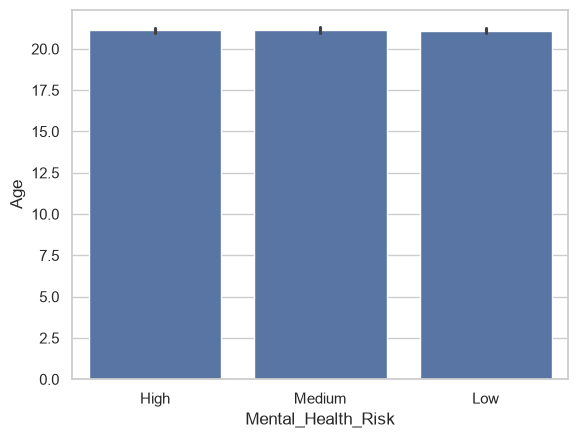

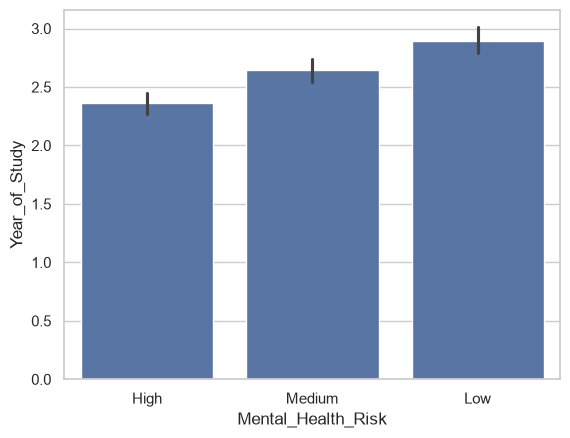

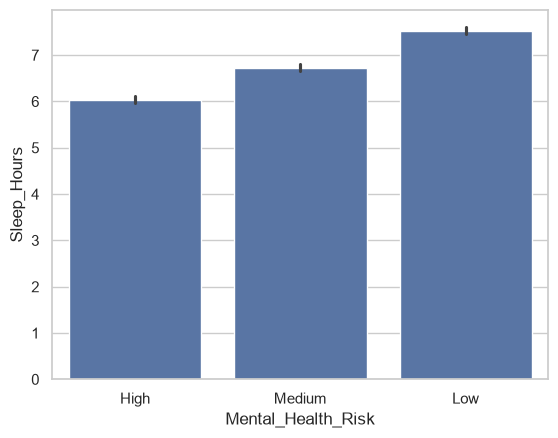

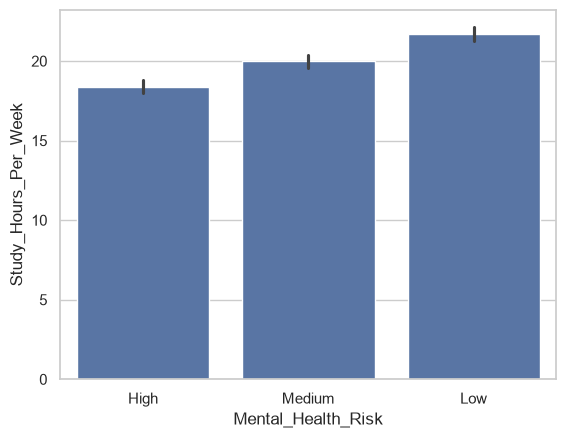

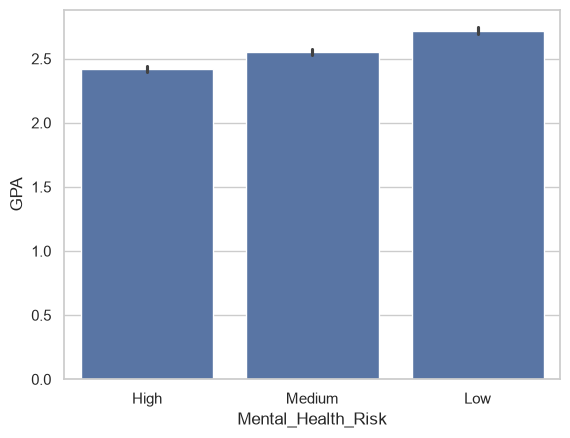

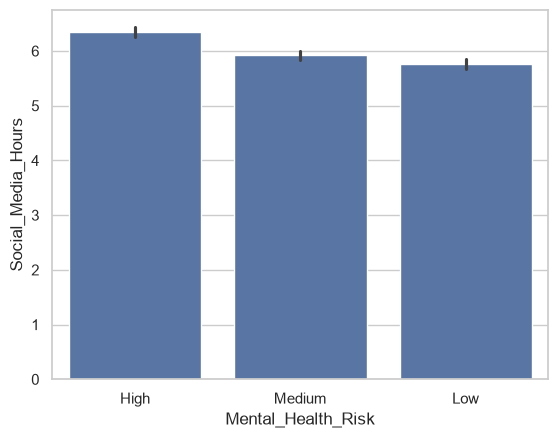

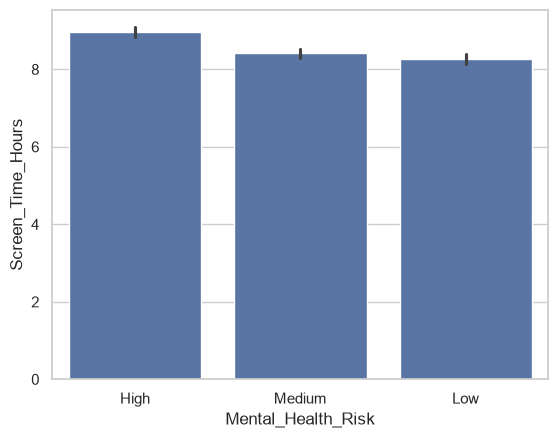

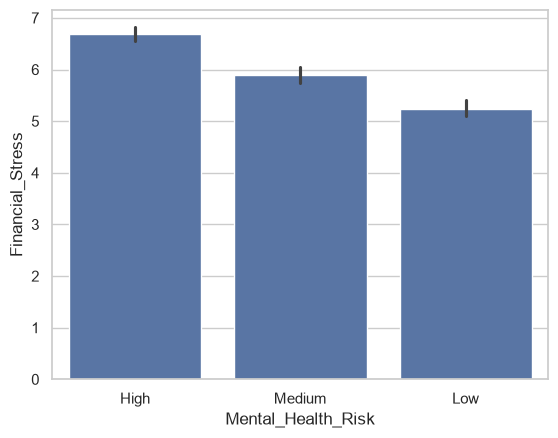

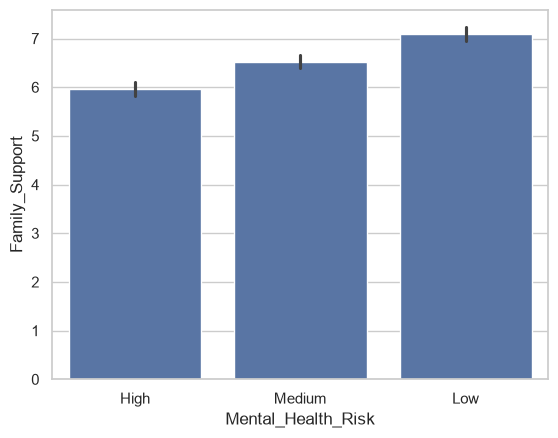

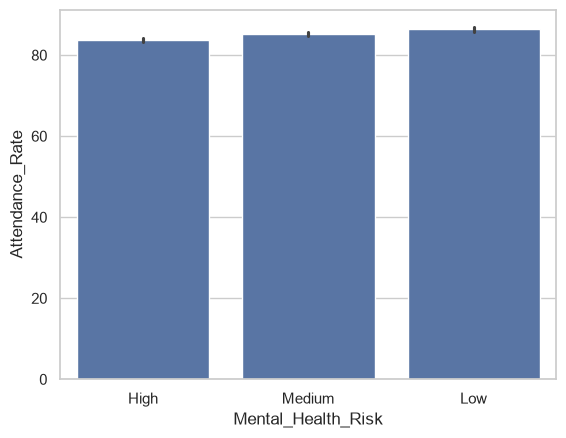

In [63]:
# relationship between numerical columns and the target
for col in numerical_columns:
    if col != 'Student_ID':
        sns.barplot(data = df , x = "Mental_Health_Risk" , y = col)
        plt.show()

C:\Users\Youcode\AppData\Local\Temp\ipykernel_17160\2781699455.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include = 'object').columns


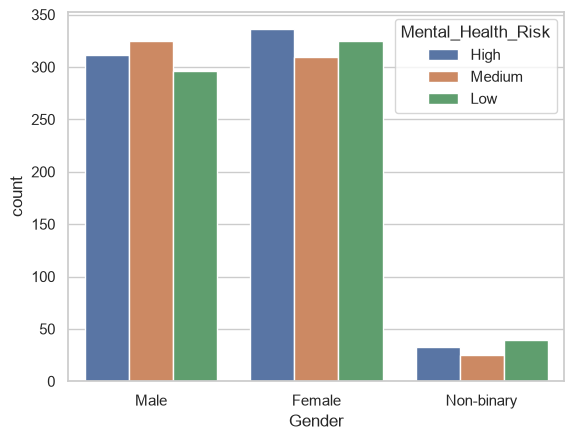

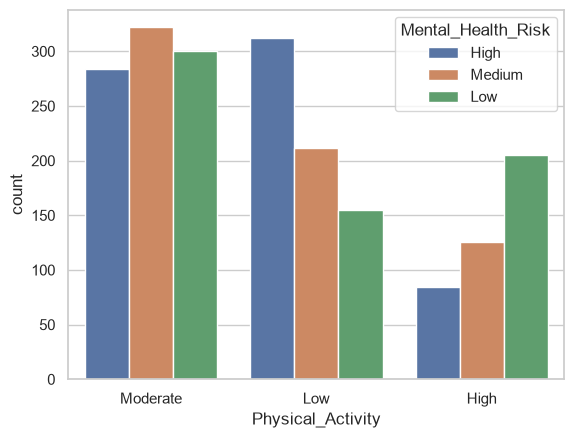

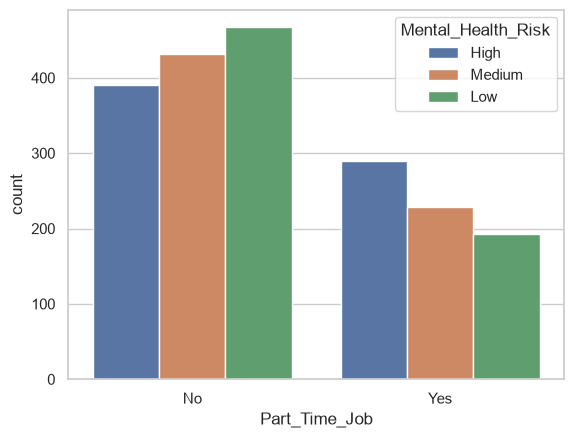

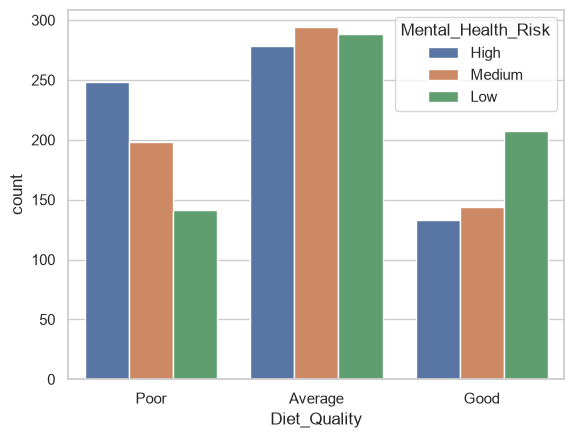

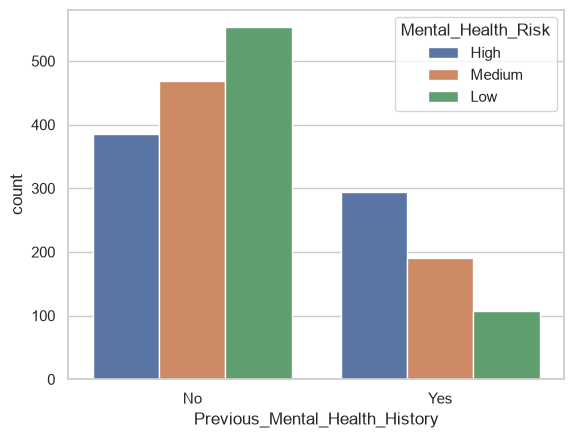

In [62]:
# relationship between categorical columns and the target
categorical_columns = df.select_dtypes(include = 'object').columns

for col in categorical_columns:
    if col not in ['Student_ID', 'Mental_Health_Risk']:
            sns.countplot(x = df[col] , hue= df['Mental_Health_Risk'])
            plt.show()

<Axes: >

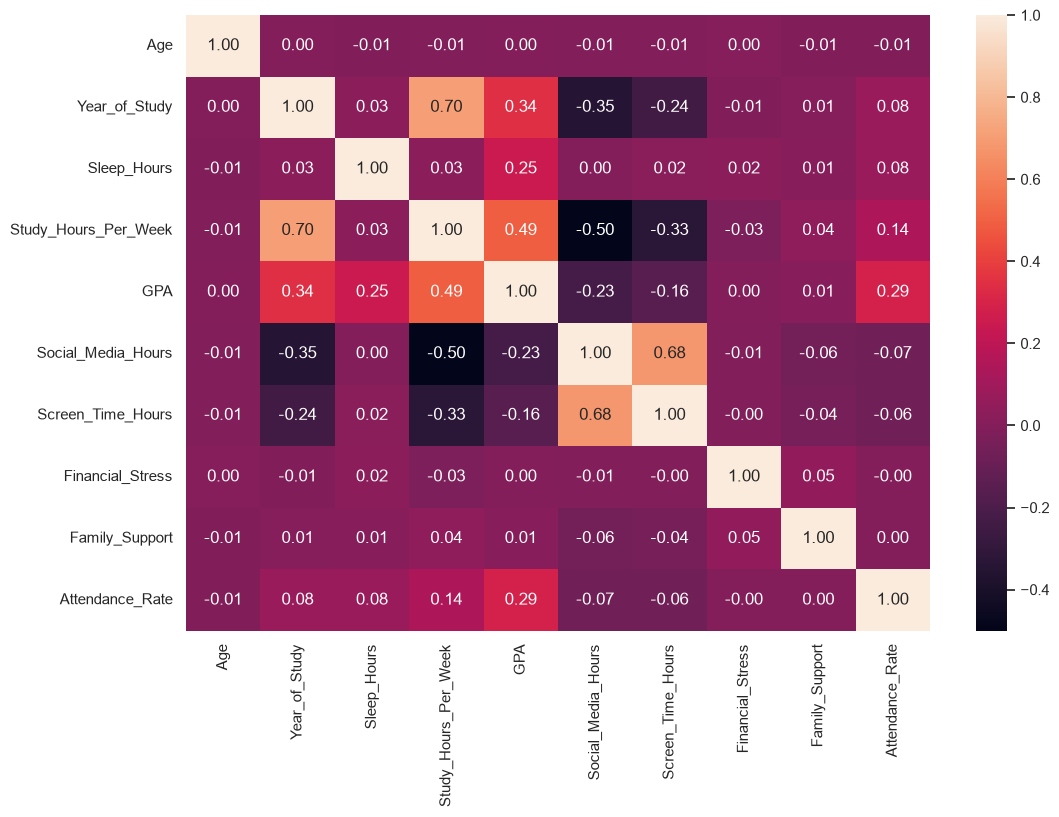

In [ ]:
# correlation between variables
corr = df.corr(numeric_only=True)
plt.figure(figsize=(12,8))
sns.heatmap(corr , annot=True , fmt='.2f')

based on the previous vidualisations and results : **Diet_Quality , Physical_Activity,Previous_Mental_Health_History,Part_Time_Job Sleep_Hours, Study_Hours_Per_Week, Financial_Stress, Family_Support** are most strongly associated with risk



In [ ]:
# age problems

df[(df['Age'] < 0) & (df['Age'] > 150)] # not found 

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk


In [4]:
# age vs Year_of_Study
df[(df['Age'] <= 20) & (df['Year_of_Study'] >= 4)].sort_values(['Age', 'Year_of_Study'] , ascending=[True , False])

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
37,STU0038,17,Female,5,6.3,28.2,2.33,6.0,6.7,Moderate,3.3,8.3,92.7,No,Poor,Yes,Medium
442,STU0443,17,Male,5,6.6,26.5,2.10,3.5,4.9,High,5.4,3.3,70.6,No,Average,No,Medium
520,STU0521,17,Male,5,7.2,24.2,2.82,4.5,8.7,Moderate,7.6,6.4,91.6,No,Average,No,Low
526,STU0527,17,Female,5,6.2,31.0,2.63,6.1,9.4,High,9.0,8.6,72.6,No,Average,No,Low
635,STU0636,17,Male,5,7.0,25.2,2.46,5.5,8.3,Moderate,4.7,7.9,90.0,No,Average,No,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1672,STU1673,20,Male,4,7.3,22.5,3.12,6.7,10.0,High,4.2,7.1,88.6,No,Good,No,Low
1691,STU1692,20,Male,4,5.7,26.7,2.51,4.2,6.8,Low,6.4,8.4,94.1,No,Poor,Yes,High
1752,STU1753,20,Male,4,4.5,20.5,2.41,6.1,8.2,High,NaN,7.8,92.1,No,Average,Yes,Medium
1855,STU1856,20,Male,4,7.6,24.6,2.54,7.5,11.4,Low,6.8,8.3,79.2,Yes,Average,Yes,High


In [81]:
# check if Screen_Time_Hours < Social_Media_Hours

result = df[df['Screen_Time_Hours'] < df['Social_Media_Hours']]
result
# len(result)

,Student_ID,Age,Gender,Year_of_Study,Sleep_Hours,Study_Hours_Per_Week,GPA,Social_Media_Hours,Screen_Time_Hours,Physical_Activity,Financial_Stress,Family_Support,Attendance_Rate,Part_Time_Job,Diet_Quality,Previous_Mental_Health_History,Mental_Health_Risk
78,STU0079,21,Male,2,5.3,17.0,2.54,5.0,4.9,Moderate,2.9,3.6,88.3,Yes,Good,Yes,High
168,STU0169,20,Female,3,6.2,25.7,2.47,5.6,5.3,Moderate,4.6,7.5,88.7,Yes,Average,Yes,Medium
209,STU0210,29,Female,4,6.5,22.1,3.02,7.5,7.3,Moderate,7.8,6.9,90.4,Yes,NaN,No,Low
278,STU0279,21,Female,3,6.7,17.9,2.54,6.0,5.1,High,6.5,7.6,81.3,No,Good,Yes,Medium
382,STU0383,17,Female,2,8.7,20.4,2.82,5.3,4.1,Low,3.8,8.8,90.5,Yes,Poor,Yes,Medium
424,STU0425,22,Female,3,8.6,20.9,2.27,5.5,4.4,Moderate,4.3,6.3,80.6,Yes,Average,No,Low
476,STU0477,22,Male,5,5.9,34.4,2.92,5.5,5.3,Moderate,2.4,3.8,91.5,Yes,Average,No,Low
505,STU0506,20,Male,1,5.2,17.7,2.46,5.6,5.5,Moderate,6.5,8.7,91.8,No,Good,No,Medium
557,STU0558,20,Male,1,6.3,17.7,2.45,4.6,4.4,Moderate,8.9,4.3,98.8,No,Poor,No,High
588,STU0589,23,Female,3,6.4,26.7,NaN,5.7,5.3,Moderate,7.3,8.5,87.3,No,Average,No,Low
